# Proiect Final — Partea A: Analiză Generală

## Cuprins
1. [Formularea Problemei & Explorarea Datelor (EDA)](#1-formularea-problemei--eda)
2. [Preprocesare în Pipeline (Scalare, Codificare, Data Leakage)](#2-preprocesare-în-pipeline)
3. [Analiza Dezechilibrului (Justificarea Neacesității)](#3-dezechilibrul-claselor)
4. [Modele Propuse (Model Baseline, SVM, RandomForest)](#4-modele-implementate)
5. [Design-ul Mulțimilor de Antrenament](#5-design-mulțimi-de-antrenament)
6. [Validare Încrucișată (Cross-Validation)](#6-cross-validation)
7. [Selecția Modelelor (Grid Search)](#7-model-selection)
8. [Metrici de Evaluare & Compararea Modelelor](#8-metrici-și-comparare)
9. [Interpretarea Rezultatelor și Concluzii](#9-interpretare-și-concluzii)


# 1. Formularea Problemei & Explorarea Datelor (EDA)

## <span style="color: #5bb04a;">1.1 Formularea Problemei din Contextul Datelor</span>
* **Obiectivul Setului de Date:** Datele monitorizează condițiile climatice dintr-o casă inteligentă cu consum redus de energie pe o perioadă de 4.5 luni, folosind senzori wireless care preiau datele la intervale de 10 minute. Datele climatice interne sunt combinate cu datele meteorologice de la cea mai apropiată stație meteo (Chievres, Belgia).
* **Variabila Țintă (Target):** `Appliances` — Exprimă consumul de energie al electrocasnicelor din locuință în watt pe oră (Wh).
* **Tipul Problemei:** Aceasta este o problemă de **Regresie Supervizată**. Scopul este aproximarea unei funcții matematice capabile să anticipeze consumul viitor de energie pe baza vectorului de caracteristici climatice.
* **Semnificație Practică:** Estimarea precisă a consumului energetic permite implementarea unor sisteme inteligente de management al clădirilor pentru reducerea cheltuielilor și optimizarea sarcinii electrice în rețele de tip Smart Grid.


## <span style="color: #5bb04a;">1.2 Incarcarea datasetului</span>

In [22]:
import os
import pandas as pd

RAW_DATA_PATH = "../data/raw/energydata_complete.csv"

if not os.path.exists(RAW_DATA_PATH):
    print("Downloading raw dataset from UCI Repository...")
    
    direct_csv_url = "https://archive.ics.uci.edu/static/public/374/appliances+energy+prediction.zip"
    
    raw_df = pd.read_csv(direct_csv_url, compression = "zip")
    
    raw_df.to_csv(RAW_DATA_PATH, index=False)
    print(f"Success! Raw dataset saved in: {RAW_DATA_PATH}")
else:
    print("Raw dataset file already exists locally !")

Raw dataset file already exists locally !


## <span style="color: #5bb04a;"> 1.3 Studierea datasetului</span>

In [23]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/raw/energydata_complete.csv")

print("=== 1. DIMENSIONALITY ARCHITECTURE ===")
print(f"Total Instances (Rows): {df.shape[0]}")
print(f"Total Attributes (Columns): {df.shape[1]}\n")

print("=== 2. DATA TYPE INTEGRITY SCAN ===")
print(df.info())
print("\n")

print("=== 3. MISSING VALUES ===")
null_counts = df.isnull().sum()
print(null_counts[null_counts > 0] if null_counts.sum() > 0 else "No missing values were detected.")
print("\n")

print("=== 4. DUPLICATION ANALYSIS ===")
duplicate_count = df.duplicated().sum()
print(f"Duplicate Rows Detected: {duplicate_count}\n")

print("=== 5. RANGE BOUNDARY SUMMARY ===")
df.describe().T

=== 1. DIMENSIONALITY ARCHITECTURE ===
Total Instances (Rows): 19735
Total Attributes (Columns): 29

=== 2. DATA TYPE INTEGRITY SCAN ===
<class 'pandas.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  str    
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19735 non-null  float64
 12  RH_5         19735 non-null  float64
 13  T6           19735 non-null  float64
 14  RH_6         19735 non-null  float64
 15  T7           19735 non-null  float64
 16  RH_7

,count,mean,std,min,25%,50%,75%,max
Appliances,19735.0,97.694958,102.524891,10.000000,50.000000,60.000000,100.000000,1080.000000
lights,19735.0,3.801875,7.935988,0.000000,0.000000,0.000000,0.000000,70.000000
T1,19735.0,21.686571,1.606066,16.790000,20.760000,21.600000,22.600000,26.260000
RH_1,19735.0,40.259739,3.979299,27.023333,37.333333,39.656667,43.066667,63.360000
T2,19735.0,20.341219,2.192974,16.100000,18.790000,20.000000,21.500000,29.856667
RH_2,19735.0,40.420420,4.069813,20.463333,37.900000,40.500000,43.260000,56.026667
T3,19735.0,22.267611,2.006111,17.200000,20.790000,22.100000,23.290000,29.236000
RH_3,19735.0,39.242500,3.254576,28.766667,36.900000,38.530000,41.760000,50.163333
T4,19735.0,20.855335,2.042884,15.100000,19.530000,20.666667,22.100000,26.200000
RH_4,19735.0,39.026904,4.341321,27.660000,35.530000,38.400000,42.156667,51.090000


## <span style="color: #4a7bb0;">Observatii si concluzii</span>

### 1. Structura Datelor
- <strong><span style="color: #d65d5d;">Constatare</span>:</strong> Setul de date conține 19.735 de înregistrări și 29 de coloane. Toate atributele sunt numerice (reale sau întregi), cu excepția coloanei `date`, care este înregistrată inițial sub formă de text (`str`).
- <strong><span style="color: #5bb04a;">Decizie</span>:</strong> Vom converti coloana `date` în formatul nativ `datetime64` pentru a putea extrage caracteristici temporale (ora din zi, ziua săptămânii, luna), elemente vitale pentru modelare.

### 2. Verificarea Calității Datelor (Valori Nule și Duplicate)
- <strong><span style="color: #d65d5d;">Constatare</span>:</strong> Nu a fost identificata nicio valoare lipsă (*missing values*) și niciun rând duplicat în întregul set de date.
- <strong><span style="color: #5bb04a;">Decizie</span>:</strong> Vom simplifica arhitectura fluxului de preprocesare (*pipeline*), eliminând necesitatea de imputare a datelor (ex: `SimpleImputer`), ceea ce reduce redundanța si complexitatea codului.

### 3. Curățarea Atributelor de Control (Zgomot Artificial)
- <strong><span style="color: #d65d5d;">Constatare</span>:</strong> Variabilele `rv1` și `rv2` sunt, conform documentației oficiale UCI, variabile pur aleatoare (*Random Variables*) introduse special pentru a testa reziliența modelelor la zgomot.
- <strong><span style="color: #5bb04a;">Decizie</span>:</strong> Vom elimina definitiv din matricea de caracteristici aceste doua atribute pentru a preveni fenomenul de *overfitting*.

### 4. Analiza Distribuției Variabilei Țintă (`Appliances`)
- <strong><span style="color: #d65d5d;">Constatare</span>:</strong> Analiza statistică de bază (`.describe()`) arată un consum mediu de aproximativ 97 Wh, insa cu un prag maxim ce urcă până la 1.080 Wh. Acest lucru indica o distribuție asimetrică la dreapta (*right-skewed*) posibil generata de vârfuri ocazionale de consum.
- <strong><span style="color: #5bb04a;">Decizie</span>:</strong> Deoarece modelele liniare pot fi afectate de valori extreme și asimetrii, alegem sa aplicam o transformare logaritmică a țintei pentru a stabiliza varianța erorilor.


# 2. Preprocesare în Pipeline

## 2.1 Pregătirea datelor

În acest capitol, transformăm deciziile luate în faza de analiză anterioara într-un flux de lucru automatizat și robust.

### 1. Transformarea atributului `date`
* <strong><span style="color: #d65d5d;">Constatare</span>:</strong> Coloana `date` (format calendaristic complex) nu poate fi procesată matematic de algoritmi precum regresia liniară sau SVM. 
* <strong><span style="color: #5bb04a;">Decizie</span>:</strong> Folosim această coloană pentru a extrage două atribute numerice ciclice: `Hour` (Ora din zi, 0-23) și `DayOfWeek` (Ziua din săptămână, 0-6) și eliminăm (`drop`) coloana brută pentru a nu bloca compilarea modelelor.

In [24]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

df['date'] = pd.to_datetime(df['date'])

df = df.sort_values(by='date').reset_index(drop=True)

df['Hour'] = df['date'].dt.hour
df['DayOfWeek'] = df['date'].dt.day_of_week
df['Month'] = df['date'].dt.month
df['DayOfYear'] = df['date'].dt.dayofyear

X = df.drop(columns=['date', 'Appliances', 'rv1', 'rv2']) # Eliminarea coloanelor irelevante pentru modelare

y = np.log1p(df['Appliances']) # Transformarea logaritmică a valorilor target

C:\Users\andre\AppData\Local\Temp\ipykernel_8948\4097986284.py:12: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  df['DayOfYear'] = df['date'].dt.dayofyear


### 2. Designul mulțimii de antrenament și preveinerea fenomenului de `Data Leakage` 
* <strong><span style="color: #d65d5d;">Constatare</span>:</strong> Deoarece lucrăm cu o serie temporală, amestecarea aleatorie a datelor (`Shuffle`) ar permite modelului să folosească informații din "viitor" pentru a prezice "trecutul". De asemenea, dacă calculăm media sau deviația standard (pentru scalare) pe întregul set de date înainte de split, setul de antrenament va afla indicii statistice din setul de test.
* <strong><span style="color: #5bb04a;">Decizie</span>:</strong> 
  1. Sortăm întregul set de date strict cronologic.
  2. Realizăm o separare fixă: primele 80% din înregistrări devin setul de antrenament (**Train**), iar ultimele 20% devin setul de test (**Test**).
  3. Vom antrena transformatoarele statistice (cum este `StandardScaler`) **exclusiv** pe datele de Train, aplicându-le ulterior pe cele de Test ca o simplă transformare.

In [25]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

print(f"Total rânduri în setul inițial:  {len(df)}")
print(f"Rânduri alocate pentru Train (80%): {X_train.shape[0]}")
print(f"Rânduri alocate pentru Test  (20%): {X_test.shape[0]}")
print(f"Număr final de atribute în X:    {X_train.shape[1]}")
print("\n=== Caracteristici rămase în matricea X ===")
print(list(X_train.columns))


Total rânduri în setul inițial:  19735
Rânduri alocate pentru Train (80%): 15788
Rânduri alocate pentru Test  (20%): 3947
Număr final de atribute în X:    29

=== Caracteristici rămase în matricea X ===
['lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'Hour', 'DayOfWeek', 'Month', 'DayOfYear']


## 2.2. Strategia de scalare: 
Construim un `ColumnTransformer` care aplică `StandardScaler` doar pe senzorii continui (temperaturi, umiditate, presiune), lăsând orele și zilele intacte (`passthrough`). Pentru a compara performanța, vom antrena modelele în două moduri: direct pe datele brute și prin Pipeline-ul de scalare.

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

sensor_attributes = [col for col in X_train.columns if col not in ['Hour', 'DayOfWeek', 'Month', 'DayOfYear']]

climate_preprocessor = ColumnTransformer(
    transformers=[
        ('scalare_standard', StandardScaler(), sensor_attributes)
    ],
    remainder='passthrough'
)

print(f"Număr de atribute ce vor fi scalate: {len(sensor_attributes)}")
print(f"Atribute pass-through: ['Hour', 'DayOfWeek', 'Month', 'DayOfYear']")

Număr de atribute ce vor fi scalate: 25
Atribute pass-through: ['Hour', 'DayOfWeek', 'Month', 'DayOfYear']


# 3. Modele Propuse

## 3.1 Definirea algoritmilor și configurarea Pipeline-urilor

Pentru faza de modelare vom selecta trei algoritmi diferiți pentru a compara capacitatea lor de predicție pe datele prelucrate:

1. **Baseline (Referință):** `LinearRegression` — un model liniar simplu pentru a stabili pragul minim de performanță.
2. **Model Kernel/Distanțe:** `SVR` (Support Vector Regression) — un algoritm puternic non-liniar, dar extrem de sensibil la scalarea datelor.
3. **Model Ansamblu:** `RandomForestRegressor` — un model bazat pe arbori de decizie, robust la asimetrii și care nu necesită neapărat scalare.

Vom integra preprocesorul definit anterior direct în obiecte de tip `Pipeline` împreună cu fiecare model.


In [27]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor

pipeline_lr_scalat = Pipeline([
    ('preprocesor', climate_preprocessor),
    ('regresie_liniara', LinearRegression())
])

pipeline_svm_scalat = Pipeline([
    ('preprocesor', climate_preprocessor),
    ('svm_regresie', SVR(C=1.0, epsilon=0.1))
])

pipeline_rf_scalat = Pipeline([
    ('preprocesor', climate_preprocessor),
    ('random_forest', RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1))
])

pipeline_lr_brut = Pipeline([('regresie_liniara', LinearRegression())])
pipeline_svm_brut = Pipeline([('svm_regresie', SVR(C=1.0, epsilon=0.1))])
pipeline_rf_brut  = Pipeline([('random_forest', RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1))])


### GRAFICE COMPARATIVE

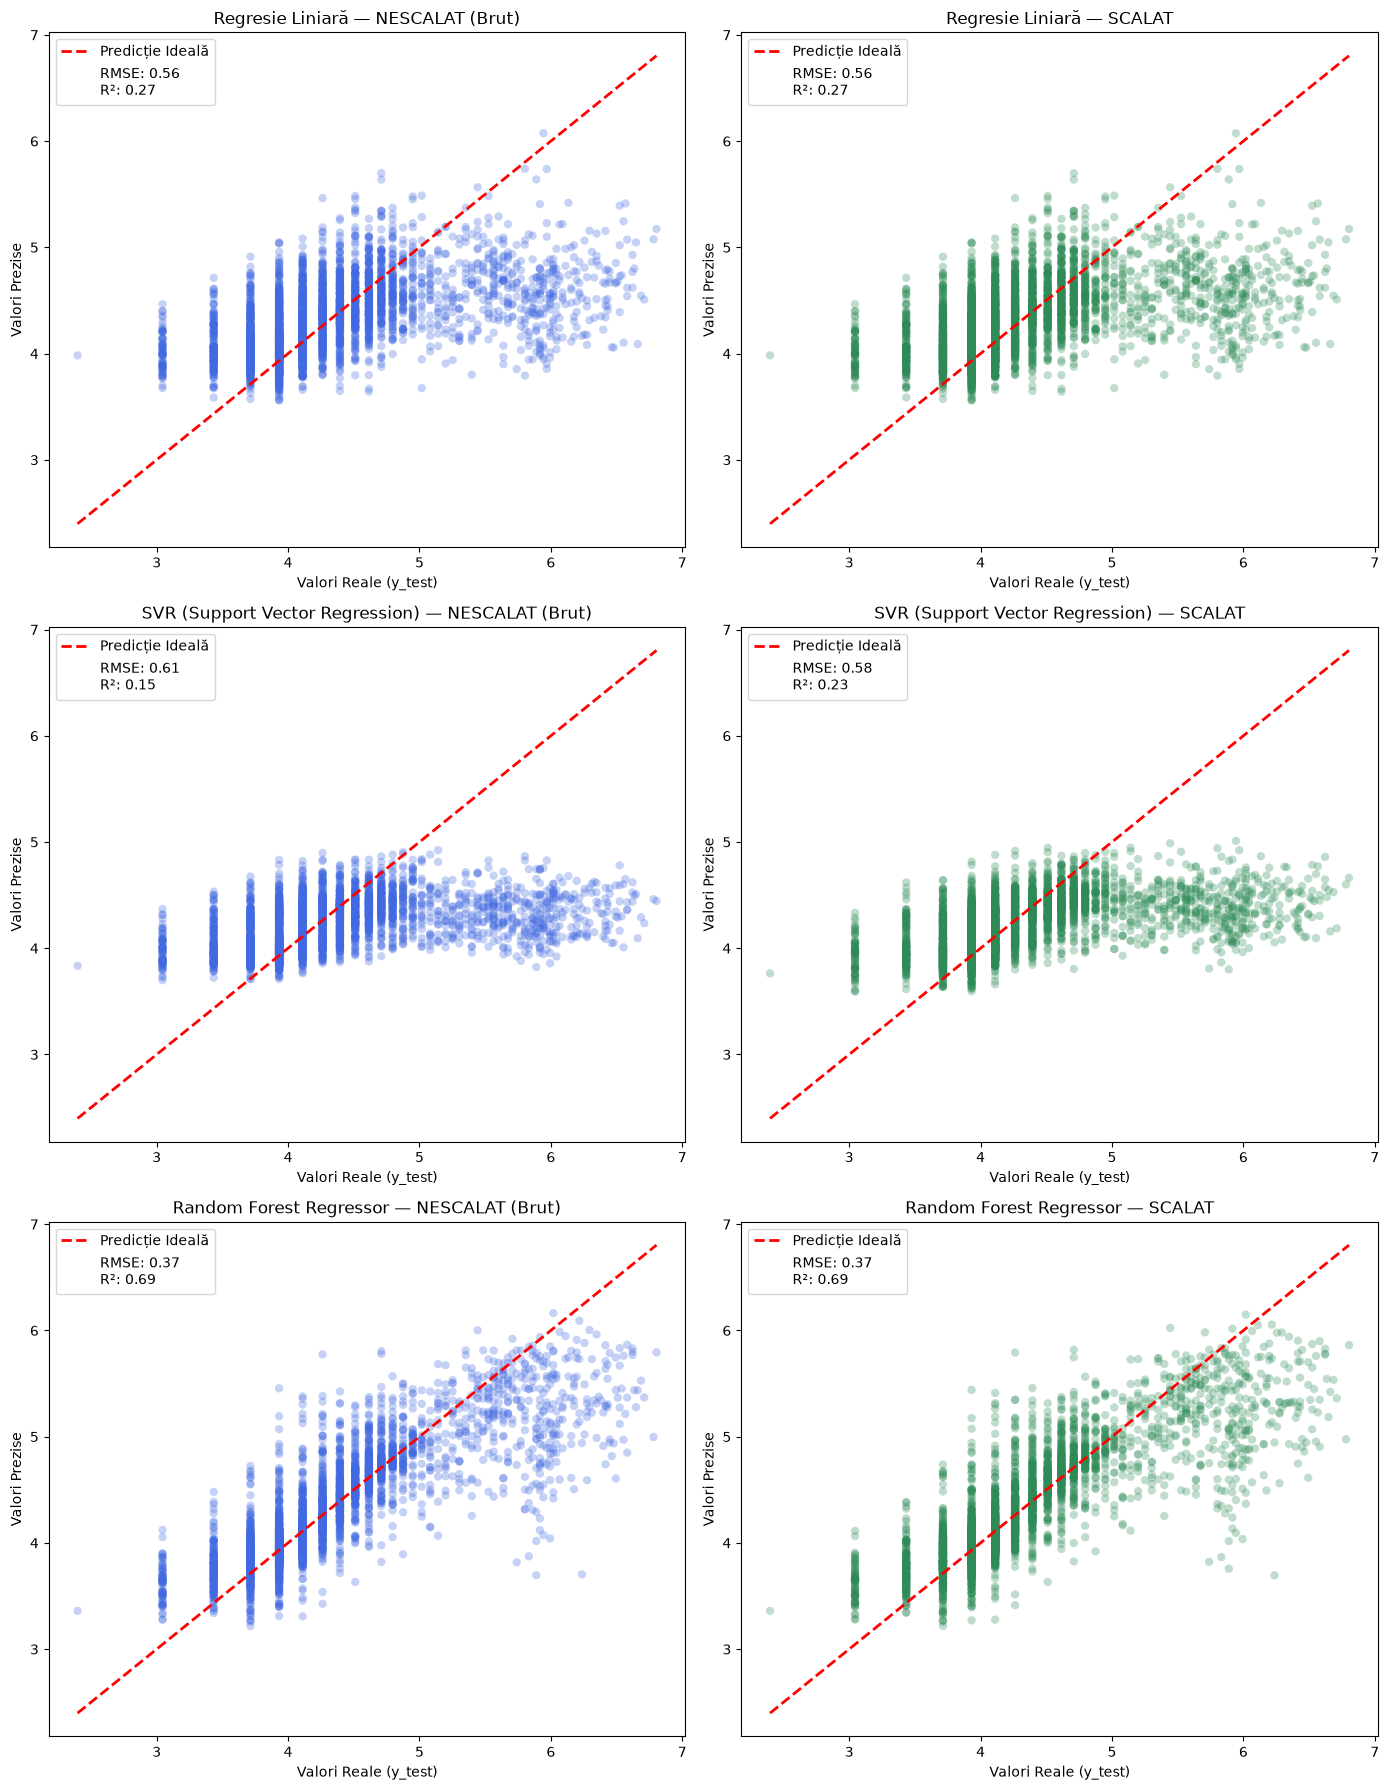

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score

pipelines = {
    'LR_Brut': pipeline_lr_brut,
    'LR_Scalat': pipeline_lr_scalat,
    'SVR_Brut': pipeline_svm_brut,
    'SVR_Scalat': pipeline_svm_scalat,
    'RF_Brut': pipeline_rf_brut,
    'RF_Scalat': pipeline_rf_scalat
}

results = {}

for name, pipe in pipelines.items():
    # Antrenare
    pipe.fit(X_train, y_train)
    
    # Predictie pe setul de test
    y_pred = pipe.predict(X_test)
    
    # Calculul metricilor
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    results[name] = {
        'y_pred': y_pred,
        'rmse': rmse,
        'r2': r2
    }

fig, axes = plt.subplots(3, 2, figsize=(14, 18))

model_rows = [
    ('Regresie Liniară', 'LR_Brut', 'LR_Scalat'),
    ('SVR (Support Vector Regression)', 'SVR_Brut', 'SVR_Scalat'),
    ('Random Forest Regressor', 'RF_Brut', 'RF_Scalat')
]

y_min, y_max = y_test.min(), y_test.max()

for i, (model_title, key_brut, key_scalat) in enumerate(model_rows):

    # Modelul Nescalat (Brut)
    ax_left = axes[i, 0]
    res_b = results[key_brut]
    ax_left.scatter(y_test, res_b['y_pred'], alpha=0.3, color='royalblue', edgecolors='none')
    ax_left.plot([y_min, y_max], [y_min, y_max], 'r--', lw=2, label='Predicție Ideală')
    
    ax_left.set_title(f"{model_title} — NESCALAT (Brut)")
    ax_left.set_xlabel("Valori Reale (y_test)")
    ax_left.set_ylabel("Valori Prezise")
    
    legend_text_b = f"RMSE: {res_b['rmse']:.2f}\nR²: {res_b['r2']:.2f}"
    ax_left.plot([], [], ' ', label=legend_text_b)
    ax_left.legend(loc='upper left', frameon=True)

    # Modelul Scalat
    ax_right = axes[i, 1]
    res_s = results[key_scalat]
    ax_right.scatter(y_test, res_s['y_pred'], alpha=0.3, color='seagreen', edgecolors='none')
    ax_right.plot([y_min, y_max], [y_min, y_max], 'r--', lw=2, label='Predicție Ideală')
    
    ax_right.set_title(f"{model_title} — SCALAT")
    ax_right.set_xlabel("Valori Reale (y_test)")
    ax_right.set_ylabel("Valori Prezise")
    
    legend_text_s = f"RMSE: {res_s['rmse']:.2f}\nR²: {res_s['r2']:.2f}"
    ax_right.plot([], [], ' ', label=legend_text_s)
    ax_right.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

## 3.2. Cross-Validation

Pentru a ne asigura că performanța modelelor noastre nu este dependentă de o singură împărțire aleatorie a setului de date (train/test), vom apela la tehnica de `Cross-Validation (Validare Încrucișată)`.

### <strong><span style="color: #d65d5d;">Observație importantă referitoare la dataset-ul nostru:</span></strong>
Deoarece setul de date *Appliances Energy Prediction* are o natură **temporală** (cronologică), utilizarea unui K-Fold clasic (care amestecă aleatoriu datele prin `shuffle=True`) ar genera *Data Leakage* (informații din viitor s-ar scurge în setul de antrenament). 

Prin urmare, pentru a respecta aspectul temporal în procesul de optimizare și validare, vom evita amestecarea aleatorie de fold-uri, asigurându-ne că modelul învață întotdeauna din trecut pentru a valida pe viitor.

### <strong><span style="color: #5bb04a;">Scopul analizei comparative:</span></strong>
În acest sens, **vom dezvolta mai departe o analiză comparativă** între două strategii distincte de validare încrucișată: `K-Fold clasic` (cu amestecare aleatorie) și `TimeSeriesSplit` (cronologică, strictă). Scopul acestei comparații este de a analiza impactul scurgerii de date (*data leakage*) asupra metricilor de performanță ($R^2$ și RMSE) și de a demonstra de ce respectarea ordinii temporale este o cerință esențială în modelarea seriilor de timp.

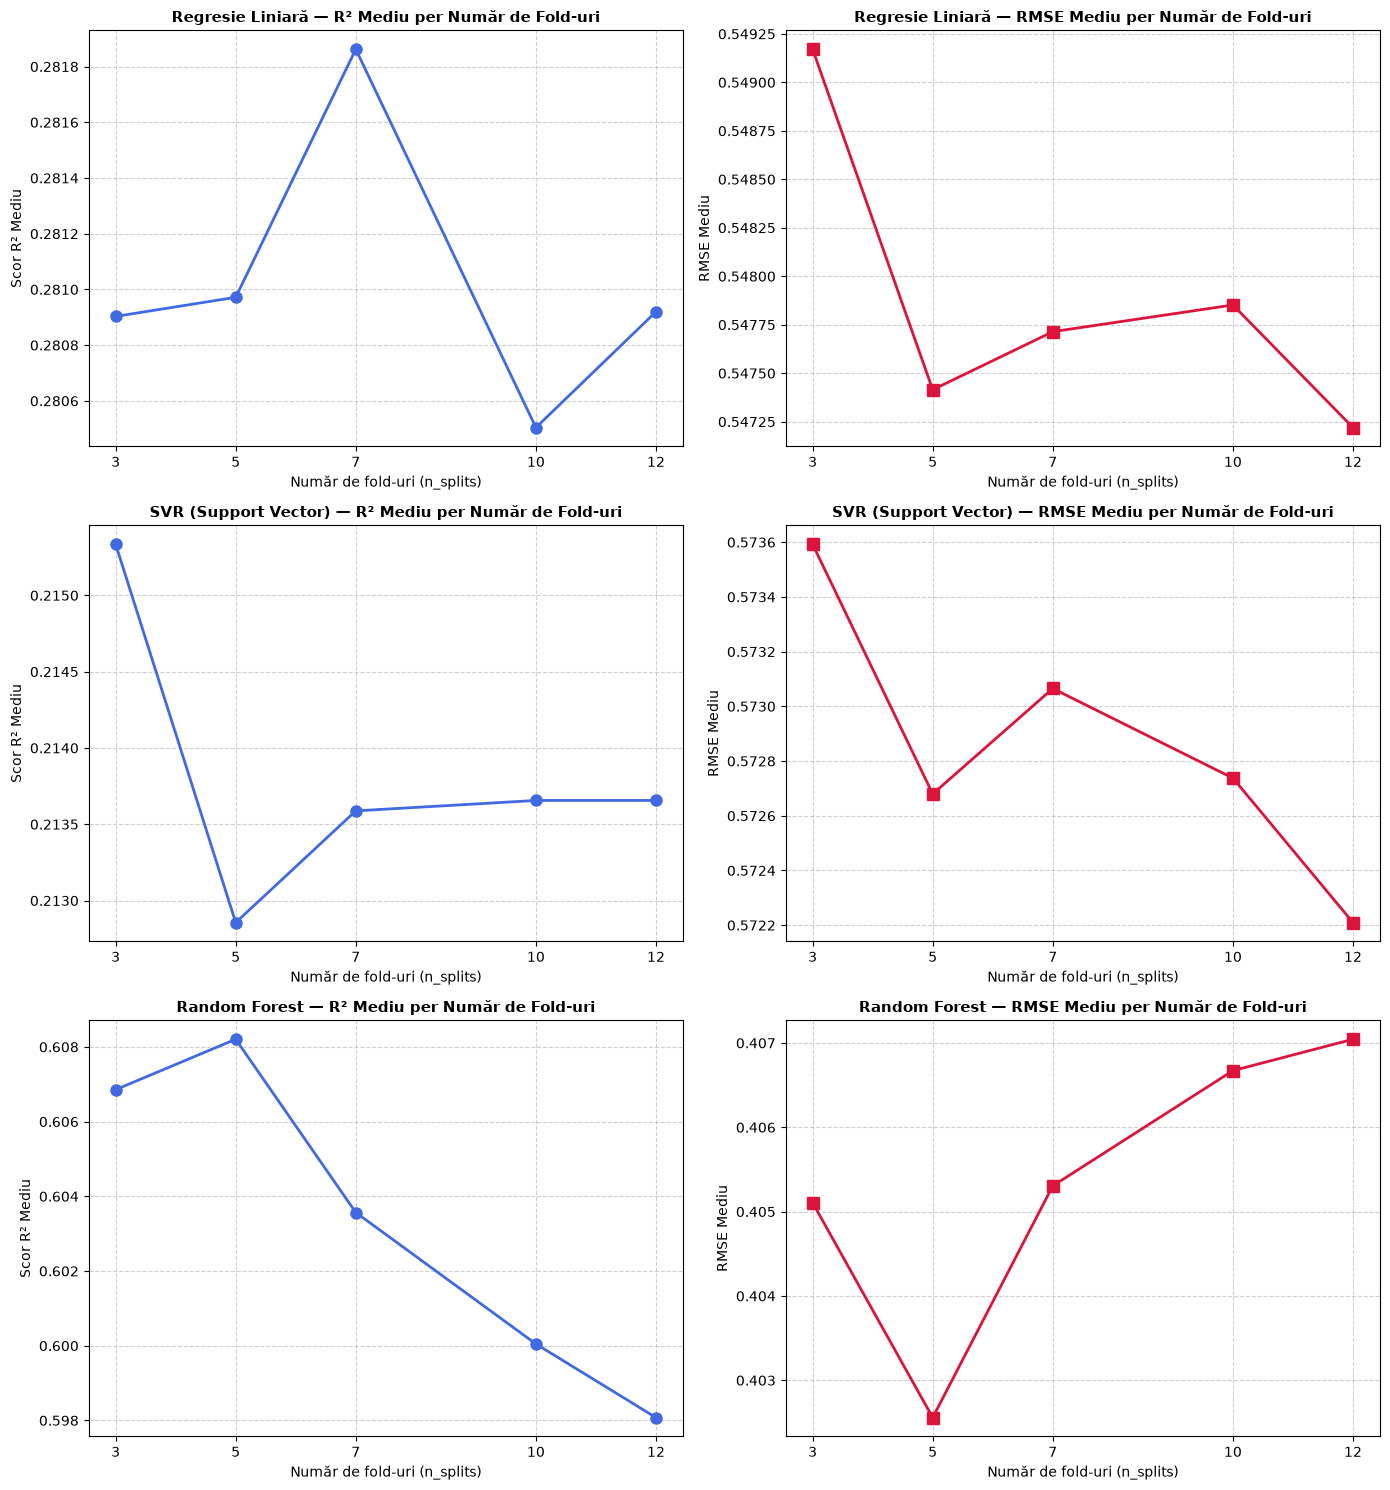

In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

models = {
    'Regresie Liniară': pipeline_lr_scalat,
    'SVR (Support Vector)': pipeline_svm_scalat,
    'Random Forest': pipeline_rf_scalat
}

fold_variants = [3, 5, 7, 10, 12]

fig, axes = plt.subplots(3, 2, figsize=(14, 15))

for i, (name, model) in enumerate(models.items()):
    medii_r2 = []
    medii_rmse = []

    for n in fold_variants:
        tscv = TimeSeriesSplit(n_splits=n)
        
        r2_scores = cross_val_score(model, X_train, y_train, cv=tscv, scoring='r2', n_jobs=-1)
        rmse_scores = -cross_val_score(model, X_train, y_train, cv=tscv, scoring='neg_root_mean_squared_error', n_jobs=-1)
        
        medii_r2.append(r2_scores.mean())
        medii_rmse.append(rmse_scores.mean())
        
    # Graficul pentru R² Mediu
    ax_r2 = axes[i, 0]
    ax_r2.plot(fold_variants, medii_r2, marker='o', linestyle='-', color='royalblue', linewidth=2, markersize=8)
    ax_r2.set_title(f"{name} — R² Mediu per Număr de Fold-uri", fontsize=11, fontweight='bold')
    ax_r2.set_xlabel("Număr de fold-uri (n_splits)", fontsize=10)
    ax_r2.set_ylabel("Scor R² Mediu", fontsize=10)
    ax_r2.set_xticks(fold_variants)
    ax_r2.grid(True, linestyle='--', alpha=0.6)
    
    # Graficul pentru RMSE Mediu
    ax_rmse = axes[i, 1]
    ax_rmse.plot(fold_variants, medii_rmse, marker='s', linestyle='-', color='crimson', linewidth=2, markersize=8)
    ax_rmse.set_title(f"{name} — RMSE Mediu per Număr de Fold-uri", fontsize=11, fontweight='bold')
    ax_rmse.set_xlabel("Număr de fold-uri (n_splits)", fontsize=10)
    ax_rmse.set_ylabel("RMSE Mediu", fontsize=10)
    ax_rmse.set_xticks(fold_variants)
    ax_rmse.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

## 4. GridSearch CV

In [39]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

def run_grid_search(pipeline, param_grid, X_tr, y_tr, cv_strategy):
    
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        cv=cv_strategy,
        scoring='r2',
        n_jobs=-1,
        verbose=1
    )
    
    grid_search.fit(X_tr, y_tr)
    
    print(f"Cei mai buni hiperparametri găsiți: {grid_search.best_params_}")
    print(f"Cel mai bun scor R² mediu (în CV): {grid_search.best_score_:.3f}")
    
    return grid_search.best_estimator_

### LinearRegression

În cazul modelului de Regresie Liniară simplă (bazat pe metoda celor mai mici pătrate ordinare), nu s-a aplicat căutarea de tip GridSearchCV. Acest lucru se datorează faptului că modelul liniar clasic este un estimator analitic pur, fără hiperparametri care să necesite tuning. Prin urmare, Regresia Liniară a fost păstrată în forma sa standard, servind strict ca punct de referință (baseline) pentru a evalua raportul de performanță adus de modelele mai complexe (Random Forest și SVR).”

### SVR

In [44]:
param_grid_svr = {
    'svm_regresie__C': [1, 10, 50],             # Forta de regularizare
    'svm_regresie__epsilon': [0.01, 0.1, 0.2],   # Marja de toleranta la eroare
    'svm_regresie__gamma': ['scale', 'auto']     # Coeficientul pentru kernel-ul RBF
}


best_svr_model = run_grid_search(pipeline_svm_scalat, param_grid_svr, X_train, y_train, tscv)

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Cei mai buni hiperparametri găsiți: {'svm_regresie__C': 10, 'svm_regresie__epsilon': 0.2, 'svm_regresie__gamma': 'auto'}
Cel mai bun scor R² mediu (în CV): 0.543


### RandomForest

In [ ]:
param_grid_rf = {
    'random_forest__n_estimators': [50, 100, 200],
    'random_forest__max_depth': [10, 20, None],
    'random_forest__min_samples_split': [2, 5]
}

tscv = TimeSeriesSplit(n_splits=5)

best_rf_model = run_grid_search(pipeline_rf_scalat, param_grid_rf, X_train, y_train, tscv)

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Cei mai buni hiperparametri găsiți: {'random_forest__max_depth': None, 'random_forest__min_samples_split': 2, 'random_forest__n_estimators': 200}
Cel mai bun scor R² mediu (în CV): 0.614




                      Model  R2 Mediu  RMSE Mediu
Baseline (Regresie Liniară)  0.280972    0.547415
              SVR (Default)  0.212856    0.572680
            SVR (Optimizat)  0.543439    0.434215
    Random Forest (Default)  0.608206    0.402558
  Random Forest (Optimizat)  0.613657    0.399742


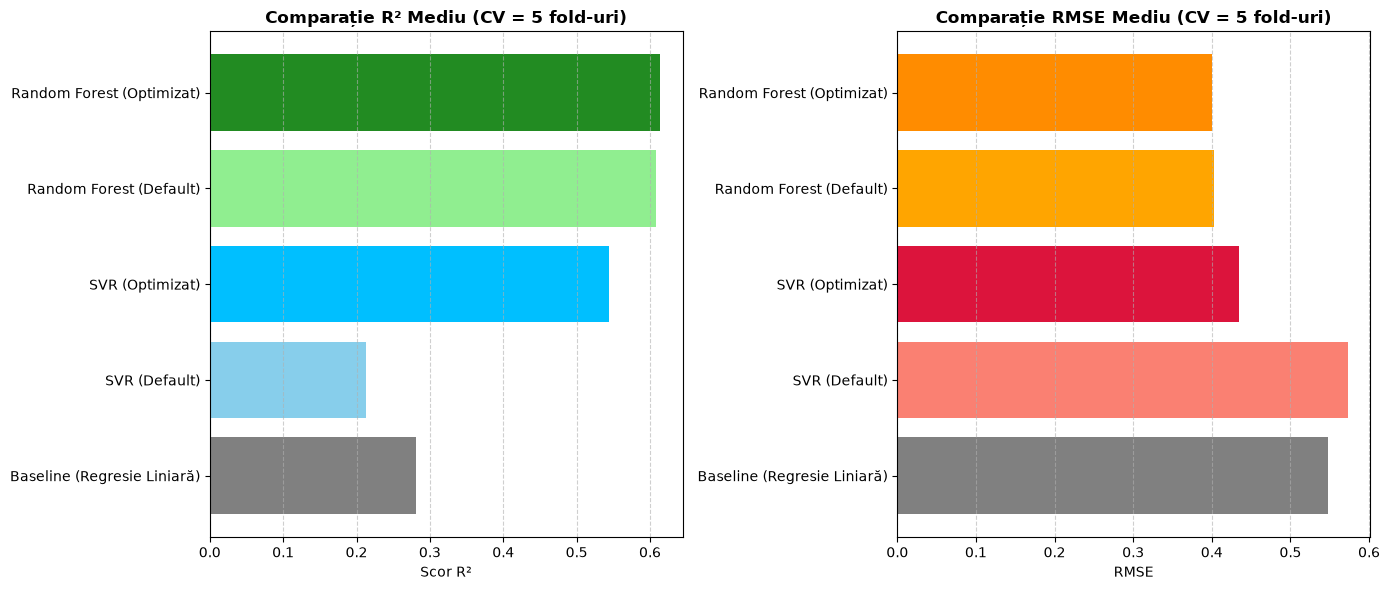

In [46]:
tscv_standard = TimeSeriesSplit(n_splits=5)

models_to_compare = {
    'Baseline (Regresie Liniară)': pipeline_lr_scalat,
    'SVR (Default)': pipeline_svm_scalat,
    'SVR (Optimizat)': best_svr_model,          
    'Random Forest (Default)': pipeline_rf_scalat,
    'Random Forest (Optimizat)': best_rf_model 
}

comparison_data = []

for name, model in models_to_compare.items():
    
    r2_scores = cross_val_score(model, X_train, y_train, cv=tscv_standard, scoring='r2', n_jobs=-1)
    rmse_scores = -cross_val_score(model, X_train, y_train, cv=tscv_standard, scoring='neg_root_mean_squared_error', n_jobs=-1)
    
    comparison_data.append({
        'Model': name,
        'R2 Mediu': r2_scores.mean(),
        'RMSE Mediu': rmse_scores.mean()
    })

df_results = pd.DataFrame(comparison_data)
print("\n")
print(df_results.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(df_results['Model'], df_results['R2 Mediu'], color=['gray', 'skyblue', 'deepskyblue', 'lightgreen', 'forestgreen'])
axes[0].set_title('Comparație R² Mediu (CV = 5 fold-uri)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Scor R²', fontsize=10)
axes[0].grid(axis='x', linestyle='--', alpha=0.6)

axes[1].barh(df_results['Model'], df_results['RMSE Mediu'], color=['gray', 'salmon', 'crimson', 'orange', 'darkorange'])
axes[1].set_title('Comparație RMSE Mediu (CV = 5 fold-uri)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('RMSE', fontsize=10)
axes[1].grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

## 5. Feature Importances

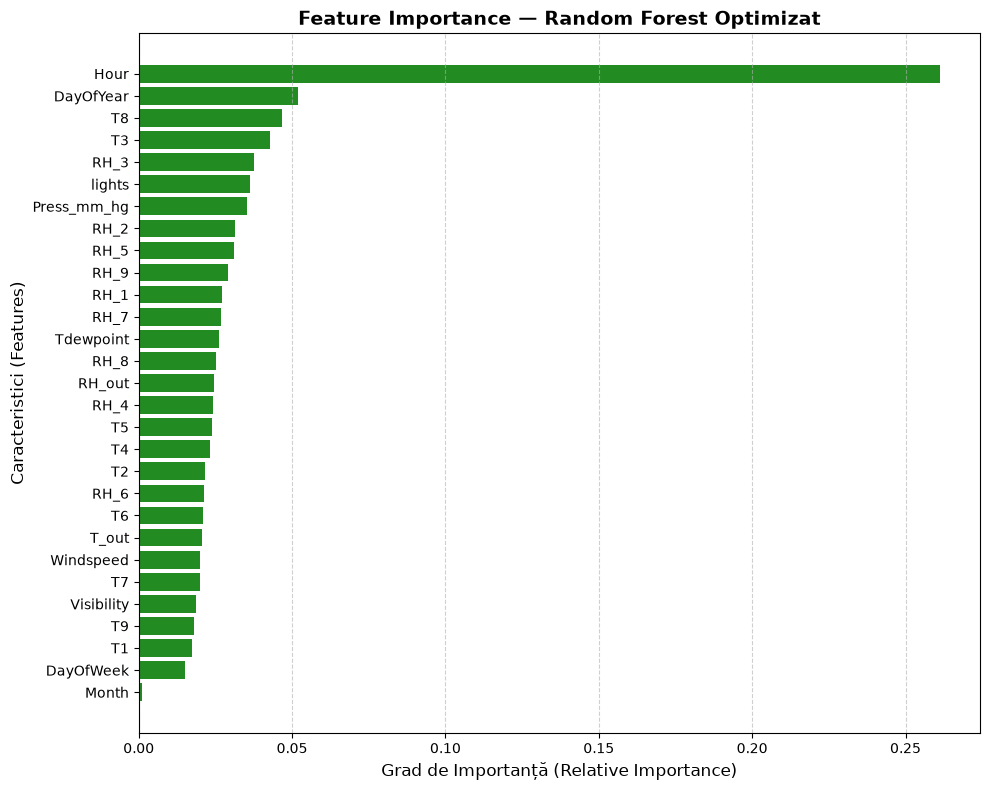

In [47]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

rf_estimator = best_rf_model.named_steps['random_forest']

feature_names = best_rf_model.named_steps['preprocesor'].get_feature_names_out()

importances = rf_estimator.feature_importances_

df_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=True)

df_importance['Feature'] = df_importance['Feature'].str.replace('scalare_standard__', '').str.replace('remainder__', '')

plt.figure(figsize=(10, 8))
plt.barh(df_importance['Feature'], df_importance['Importance'], color='forestgreen')
plt.title('Feature Importance — Random Forest Optimizat', fontsize=14, fontweight='bold')
plt.xlabel('Grad de Importanță (Relative Importance)', fontsize=12)
plt.ylabel('Caracteristici (Features)', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()